# Corrigé — Étalonnage de capteurs et régression par moindres carrés

Ce notebook résout les exercices du chapitre 4. Pour chaque question, la cellule Markdown résume la démarche ; la cellule Python fait l'application numérique.

Les fichiers de données (`cellule_charge.csv`, `pitot.csv`, `pt100_*.csv`, `photodiode_voc.csv`) doivent se trouver dans le sous-répertoire `donnees/`, à côté de ce notebook.

**Rappel.** Pour un modèle linéaire en ses coefficients, $\mathbf{y} = \mathbf{X}\mathbf{a} + \mathbf{r}$, la solution des moindres carrés vérifie les équations normales

$$
\mathbf{X}^\mathsf{T}\mathbf{X}\,\hat{\mathbf{a}} = \mathbf{X}^\mathsf{T}\mathbf{y}.
$$

En NumPy, on utilise `np.linalg.lstsq(X, y)`, numériquement plus stable que l'inversion de $\mathbf{X}^\mathsf{T}\mathbf{X}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from pathlib import Path

DATA = Path("donnees")

def lire(nom):
    # Lit un fichier CSV à deux colonnes (ligne d'en-tête ignorée)
    return np.loadtxt(DATA / nom, delimiter=",", skiprows=1, unpack=True)

## Exercice 1 — Régression « à la main » avec peu de points

Une cellule de charge est étalonnée avec cinq masses étalons $m_i$ ; on mesure la tension de sortie du pont $U_i$ en mV. Modèle : $U = a_0 + a_1 m$.

In [2]:
m, U = lire("cellule_charge.csv")
n = len(m)
for mi, ui in zip(m, U):
    print(f"m = {mi:5.3f} kg   U = {ui:.4f} mV")

m = 0.000 kg   U = 0.0864 mV
m = 0.500 kg   U = 0.2893 mV
m = 1.000 kg   U = 0.4884 mV
m = 2.000 kg   U = 0.8840 mV
m = 5.000 kg   U = 2.0991 mV


### Question 1.1 — Vecteur $\mathbf{y}$ et matrice $\mathbf{X}$

Chaque mesure donne une ligne $U_i = a_0 \cdot 1 + a_1 \cdot m_i$. La matrice $\mathbf{X}$ a donc une colonne de 1 (pour $a_0$) et une colonne contenant les masses (pour $a_1$) :

$$
\mathbf{y} = \begin{pmatrix} U_1 \\ \vdots \\ U_5 \end{pmatrix},
\qquad
\mathbf{X} = \begin{pmatrix} 1 & m_1 \\ \vdots & \vdots \\ 1 & m_5 \end{pmatrix},
\qquad
\mathbf{a} = \begin{pmatrix} a_0 \\ a_1 \end{pmatrix}.
$$

In [3]:
X = np.column_stack([np.ones_like(m), m])
y = U
print("X =\n", X)
print("y =", y)

X =
 [[1.  0. ]
 [1.  0.5]
 [1.  1. ]
 [1.  2. ]
 [1.  5. ]]
y = [0.0864 0.2893 0.4884 0.884  2.0991]


### Question 1.2 — Calcul de $\mathbf{X}^\mathsf{T}\mathbf{X}$ et $\mathbf{X}^\mathsf{T}\mathbf{y}$ avec SymPy

On construit $\mathbf{X}$ et $\mathbf{y}$ avec des **symboles** $m_1 \dots m_5$, $U_1 \dots U_5$, puis on laisse SymPy faire les produits matriciels. On reconnaît ensuite les sommes dans chaque élément.

In [4]:
ms = sp.symbols("m1:6")      # m1, ..., m5
Us = sp.symbols("U1:6")      # U1, ..., U5

Xs = sp.Matrix([[1, mi] for mi in ms])
ys = sp.Matrix(Us)

XtX_s = Xs.T * Xs
Xty_s = Xs.T * ys
display(Xs, XtX_s, Xty_s)

Matrix([
[1, m1],
[1, m2],
[1, m3],
[1, m4],
[1, m5]])

Matrix([
[                     5,                m1 + m2 + m3 + m4 + m5],
[m1 + m2 + m3 + m4 + m5, m1**2 + m2**2 + m3**2 + m4**2 + m5**2]])

Matrix([
[               U1 + U2 + U3 + U4 + U5],
[U1*m1 + U2*m2 + U3*m3 + U4*m4 + U5*m5]])

On lit directement :

$$
\mathbf{X}^\mathsf{T}\mathbf{X} = \begin{pmatrix} n & \sum m_i \\ \sum m_i & \sum m_i^2 \end{pmatrix},
\qquad
\mathbf{X}^\mathsf{T}\mathbf{y} = \begin{pmatrix} \sum U_i \\ \sum m_i U_i \end{pmatrix}.
$$

- l'élément $(1,1)$ est la somme de $1 \cdot 1$ sur les 5 lignes, donc $n = 5$ ;
- les éléments hors diagonale valent $\sum m_i$ ;
- l'élément $(2,2)$ vaut $\sum m_i^2$ ;
- $\mathbf{X}^\mathsf{T}\mathbf{y}$ contient $\sum U_i$ et $\sum m_i U_i$.

Application numérique : on remplace les symboles par les mesures, et on vérifie avec NumPy.

In [5]:
valeurs = dict(zip(ms, m)) | dict(zip(Us, U))
display(XtX_s.subs(valeurs).evalf(6), Xty_s.subs(valeurs).evalf(6))

XtX = X.T @ X
Xty = X.T @ y
print("NumPy : XᵀX =\n", XtX)
print("NumPy : Xᵀy =", Xty)

Matrix([
[5.0,   8.5],
[8.5, 30.25]])

Matrix([
[ 3.8472],
[12.8965]])

NumPy : XᵀX =
 [[ 5.    8.5 ]
 [ 8.5  30.25]]
NumPy : Xᵀy = [ 3.8472  12.89655]


### Question 1.3 — Résolution du système $2 \times 2$

On applique l'inverse d'une matrice $2\times 2$ :

$$
\begin{pmatrix} a & b \\ c & d \end{pmatrix}^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}
$$

à $\mathbf{X}^\mathsf{T}\mathbf{X}$, puis $\hat{\mathbf{a}} = (\mathbf{X}^\mathsf{T}\mathbf{X})^{-1}\,\mathbf{X}^\mathsf{T}\mathbf{y}$. SymPy donne la forme générale, en notant $S_m = \sum m_i$, $S_{mm} = \sum m_i^2$, $S_U = \sum U_i$ et $S_{mU} = \sum m_i U_i$ :

In [6]:
N, Sm, Smm, SU, SmU = sp.symbols("n S_{m} S_{mm} S_{U} S_{mU}")
M = sp.Matrix([[N, Sm], [Sm, Smm]])
b = sp.Matrix([SU, SmU])

display(M.inv())
a_sym = sp.simplify(M.inv() * b)
display(sp.Eq(sp.Symbol("a_0"), a_sym[0]), sp.Eq(sp.Symbol("a_1"), a_sym[1]))

Matrix([
[S_{mm}/(S_{mm}*n - S_{m}**2), -S_{m}/(S_{mm}*n - S_{m}**2)],
[-S_{m}/(S_{mm}*n - S_{m}**2),      n/(S_{mm}*n - S_{m}**2)]])

Eq(a_0, (S_{U}*S_{mm} - S_{mU}*S_{m})/(S_{mm}*n - S_{m}**2))

Eq(a_1, (-S_{U}*S_{m} + S_{mU}*n)/(S_{mm}*n - S_{m}**2))

Soit, avec le déterminant $D = n\sum m_i^2 - \left(\sum m_i\right)^2$ :

$$
a_1 = \frac{n\sum m_i U_i - \sum m_i \sum U_i}{D},
\qquad
a_0 = \frac{\sum m_i^2 \sum U_i - \sum m_i \sum m_i U_i}{D}.
$$

Application numérique avec les sommes :

In [7]:
S_m, S_mm = m.sum(), (m**2).sum()
S_U, S_mU = U.sum(), (m * U).sum()

D = n * S_mm - S_m**2
a1 = (n * S_mU - S_m * S_U) / D
a0 = (S_mm * S_U - S_m * S_mU) / D
print(f"D  = {D:.4f} kg²")
print(f"a0 = {a0:.4f} mV       (décalage)")
print(f"a1 = {a1:.4f} mV/kg    (sensibilité)")

D  = 79.0000 kg²
a0 = 0.0855 mV       (décalage)
a1 = 0.4023 mV/kg    (sensibilité)


### Question 1.4 — Vérification avec `lstsq` et `polyfit`

- `np.linalg.lstsq(X, y)` renvoie $[a_0, a_1]$, dans l'ordre des colonnes de $\mathbf{X}$ ;
- `np.polyfit(m, U, 1)` renvoie les coefficients **du plus haut degré au plus bas**, donc $[a_1, a_0]$.

In [8]:
a_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None)
a_poly = np.polyfit(m, U, 1)

print("à la main :", [a0, a1])
print("lstsq     :", a_lstsq)
print("polyfit   :", a_poly, " -> ordre inverse :", a_poly[::-1])

à la main : [0.08553322784810129, 0.4022981012658227]
lstsq     : [0.08553323 0.4022981 ]
polyfit   : [0.4022981  0.08553323]  -> ordre inverse : [0.08553323 0.4022981 ]


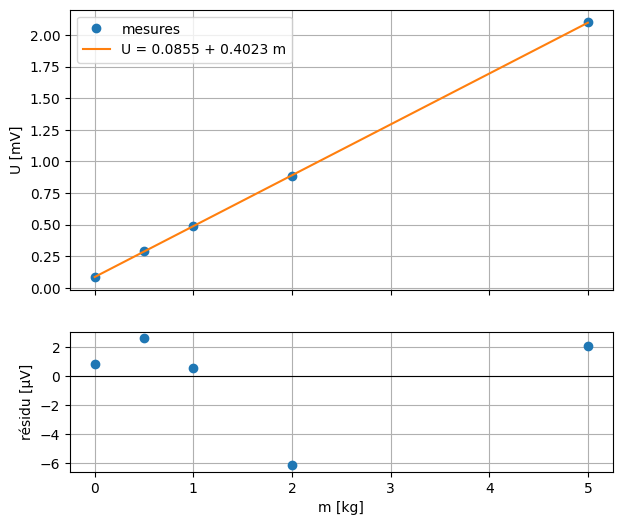

In [9]:
residus = U - (a0 + a1 * m)
m_fin = np.linspace(0, m.max(), 100)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6), height_ratios=[2, 1])
ax1.plot(m, U, "o", label="mesures")
ax1.plot(m_fin, a0 + a1 * m_fin, label=f"U = {a0:.4f} + {a1:.4f} m")
ax1.set_ylabel("U [mV]"); ax1.legend(); ax1.grid()
ax2.plot(m, residus * 1000, "o")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_xlabel("m [kg]"); ax2.set_ylabel("résidu [µV]"); ax2.grid()
plt.show()

### Question 1.5 — Utilisation de l'étalonnage

On inverse le modèle : $m = \dfrac{U - a_0}{a_1}$.

In [10]:
U_lu = 1.234   # mV
m_lu = (U_lu - a0) / a1
print(f"U = {U_lu} mV  ->  m = {m_lu:.4f} kg")

U = 1.234 mV  ->  m = 2.8548 kg


## Exercice 2 — Tube de Pitot : une caractéristique quadratique

Bernoulli donne $\Delta p = C\,\tfrac{1}{2}\rho v^2$. Avec le décalage de zéro du capteur, le modèle attendu est $\Delta p = \Delta p_0 + k v^2$, avec $k = C\rho/2$.

### Question 2.1 — Tracé des données

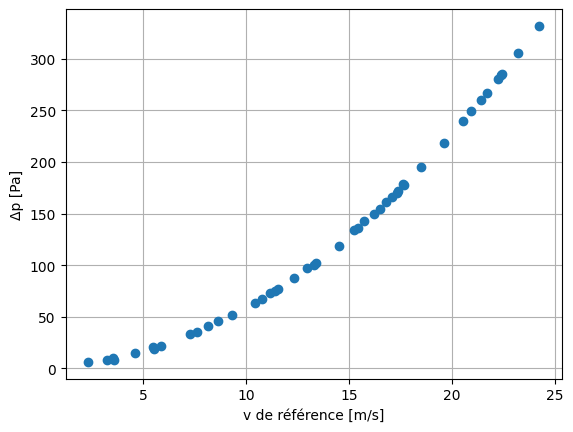

In [11]:
v, dp = lire("pitot.csv")

plt.plot(v, dp, "o")
plt.xlabel("v de référence [m/s]"); plt.ylabel("Δp [Pa]"); plt.grid()
plt.show()

La courbe est convexe : $\Delta p$ croît de plus en plus vite avec $v$, ce qui est cohérent avec une loi en $v^2$.

### Question 2.2 — Ajustement d'une droite

Modèle $\Delta p = a_0 + a_1 v$, donc $\mathbf{X} = [\,1,\ v\,]$. On trace la droite sur les données, puis les résidus $r_i = \Delta p_i - (a_0 + a_1 v_i)$.

Δp = -73.56 + 14.833 v


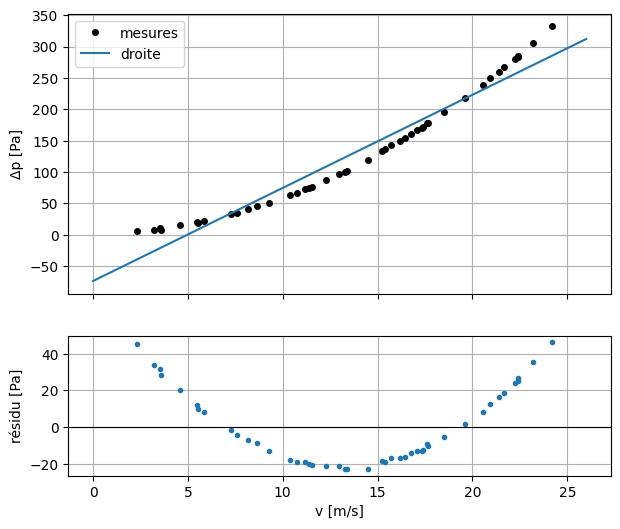

In [12]:
Xd = np.column_stack([np.ones_like(v), v])
a_droite, *_ = np.linalg.lstsq(Xd, dp, rcond=None)
r_droite = dp - Xd @ a_droite
print(f"Δp = {a_droite[0]:.2f} + {a_droite[1]:.3f} v")

v_fin = np.linspace(0, 26, 300)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6), height_ratios=[2, 1])
ax1.plot(v, dp, "ko", ms=4, label="mesures")
ax1.plot(v_fin, a_droite[0] + a_droite[1] * v_fin, label="droite")
ax1.set_ylabel("Δp [Pa]"); ax1.legend(); ax1.grid()
ax2.plot(v, r_droite, "o", ms=3)
ax2.axhline(0, color="k", lw=0.8)
ax2.set_xlabel("v [m/s]"); ax2.set_ylabel("résidu [Pa]"); ax2.grid()
plt.show()

La droite semble suivre la tendance, mais ses résidus forment un **U** de plusieurs dizaines de pascals : négatifs au milieu, positifs aux extrémités. Ce n'est pas du bruit : la structure montre qu'il manque un terme quadratique.

### Question 2.3 — Parabole complète

Modèle $\Delta p = a_0 + a_1 v + a_2 v^2$, donc $\mathbf{X} = [\,1,\ v,\ v^2\,]$.

In [13]:
Xp = np.column_stack([np.ones_like(v), v, v**2])
a_par, *_ = np.linalg.lstsq(Xp, dp, rcond=None)
r_par = dp - Xp @ a_par
print(f"a0 = {a_par[0]:.3f} Pa,   a1 = {a_par[1]:.4f} Pa/(m/s),   a2 = {a_par[2]:.4f} Pa/(m/s)²")

a0 = 2.715 Pa,   a1 = -0.0412 Pa/(m/s),   a2 = 0.5641 Pa/(m/s)²


**Le terme $a_1 v$ est-il négligeable ?** On ne peut pas comparer directement $a_1$ et $a_2$ : ils n'ont pas la même unité. On compare donc ce que chaque terme **apporte au signal** $\Delta p$, en pascals, pour quelques vitesses de la plage mesurée :

- $a_1 v$ : la part du signal due au terme linéaire ;
- $a_2 v^2$ : la part due au terme quadratique.

In [14]:
for vv in [5, 10, 20, 25]:            # quelques vitesses de la plage étalonnée [m/s]
    terme_lin = a_par[1] * vv         # contribution du terme linéaire     a1·v  [Pa]
    terme_quad = a_par[2] * vv**2     # contribution du terme quadratique  a2·v² [Pa]
    print(f"v = {vv:2d} m/s :  a1·v = {terme_lin:6.2f} Pa   a2·v² = {terme_quad:6.1f} Pa")

v =  5 m/s :  a1·v =  -0.21 Pa   a2·v² =   14.1 Pa
v = 10 m/s :  a1·v =  -0.41 Pa   a2·v² =   56.4 Pa
v = 20 m/s :  a1·v =  -0.82 Pa   a2·v² =  225.6 Pa
v = 25 m/s :  a1·v =  -1.03 Pa   a2·v² =  352.6 Pa


Le terme linéaire n'apporte qu'environ 1 Pa au plus, du même ordre que le bruit du capteur (≈ 0,8 Pa), alors que le terme quadratique vaut de 14 à 350 Pa. $a_1 v$ est donc négligeable, comme le prévoit Bernoulli.

$a_0$ est la pression lue à vitesse nulle : c'est le **décalage de zéro** $\Delta p_0$ du capteur.

### Question 2.4 — Modèle physique et comparaison des résidus

Modèle $\Delta p = a_0 + a_2 v^2$, donc $\mathbf{X} = [\,1,\ v^2\,]$. On compare ensuite les résidus des trois modèles.

Δp = 2.487 + 0.5626 v²
droite    : résidu max =  46.32 Pa
parabole  : résidu max =   1.87 Pa
physique  : résidu max =   1.93 Pa


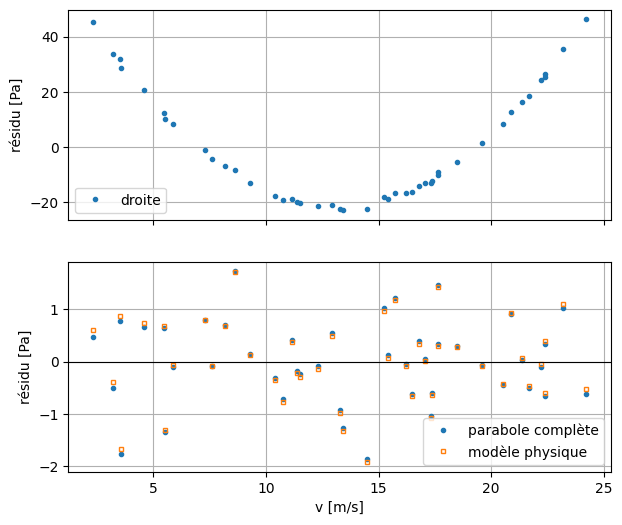

In [15]:
Xphys = np.column_stack([np.ones_like(v), v**2])
a_phys, *_ = np.linalg.lstsq(Xphys, dp, rcond=None)
r_phys = dp - Xphys @ a_phys
print(f"Δp = {a_phys[0]:.3f} + {a_phys[1]:.4f} v²")

for nom, r in [("droite", r_droite), ("parabole", r_par), ("physique", r_phys)]:
    print(f"{nom:9s} : résidu max = {np.abs(r).max():6.2f} Pa")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax1.plot(v, r_droite, "o", ms=3, label="droite")
ax1.set_ylabel("résidu [Pa]"); ax1.legend(); ax1.grid()
ax2.plot(v, r_par, "o", ms=3, label="parabole complète")
ax2.plot(v, r_phys, "s", ms=3, mfc="none", label="modèle physique")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_xlabel("v [m/s]"); ax2.set_ylabel("résidu [Pa]"); ax2.legend(); ax2.grid()
plt.show()

Les résidus de la droite sont d'un autre ordre de grandeur (graphique du haut). Ceux de la parabole et du modèle physique sont presque identiques, aléatoires et au niveau du bruit (graphique du bas). Le **modèle physique** décrit aussi bien les données avec un paramètre de moins : on le retient.

### Question 2.5 — Coefficient du tube

Avec le modèle physique, $a_2 = k = C\rho/2$, donc $C\rho = 2a_2$. La masse volumique vient de la loi des gaz parfaits, $\rho = \dfrac{p}{R_s T}$, avec $p = 956$ hPa et $T = 21$ °C.

In [16]:
dp0, k = a_phys
R_s = 287.05                      # J/(kg K)
rho = 95600 / (R_s * (273.15 + 21))
C = 2 * k / rho

print(f"Δp0 = a0 = {dp0:.3f} Pa")
print(f"k = a2 = {k:.4f} kg/m³   ->   Cρ = {2*k:.4f} kg/m³")
print(f"ρ = {rho:.4f} kg/m³   ->   C = {C:.4f}")

Δp0 = a0 = 2.487 Pa
k = a2 = 0.5626 kg/m³   ->   Cρ = 1.1252 kg/m³
ρ = 1.1322 kg/m³   ->   C = 0.9938


### Question 2.6 — Utilisation de l'étalonnage

On inverse le modèle : $v = \sqrt{\dfrac{\Delta p - a_0}{a_2}}$.

In [17]:
for dp_lu in [5, 50, 300]:
    print(f"Δp = {dp_lu:3d} Pa  ->  v = {np.sqrt((dp_lu - dp0) / k):6.2f} m/s")

Δp =   5 Pa  ->  v =   2.11 m/s
Δp =  50 Pa  ->  v =   9.19 m/s
Δp = 300 Pa  ->  v =  23.00 m/s


### Question 2.7 — Sensibilité

On dérive le modèle : $\dfrac{\mathrm{d}\Delta p}{\mathrm{d}v} = 2 a_2 v$. Une petite variation $\delta\Delta p$ produit donc $\delta v = \dfrac{\delta \Delta p}{2 a_2 v}$. En appliquant cette relation aux écarts-types :

$$
u(v) \approx \frac{u(\Delta p)}{2 a_2 v}, \qquad u(\Delta p) = 0{,}8\ \text{Pa}.
$$

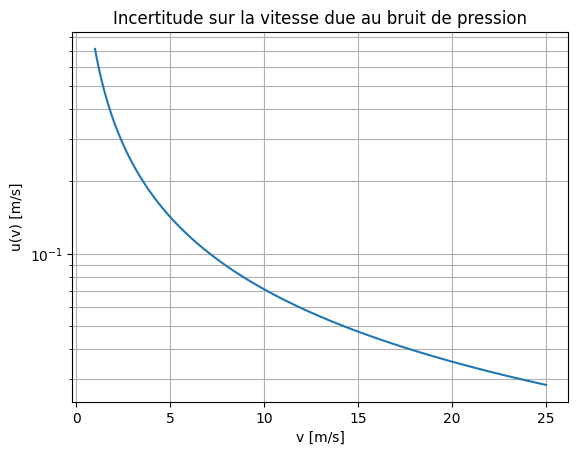

v =  1 m/s :  signal k·v² =    0.6 Pa   u(v) = 0.711 m/s
v =  5 m/s :  signal k·v² =   14.1 Pa   u(v) = 0.142 m/s
v = 20 m/s :  signal k·v² =  225.0 Pa   u(v) = 0.036 m/s


In [18]:
u_dp = 0.8
v_t = np.linspace(1, 25, 200)
u_v = u_dp / (2 * k * v_t)

plt.plot(v_t, u_v)
plt.yscale("log")
plt.xlabel("v [m/s]"); plt.ylabel("u(v) [m/s]"); plt.grid(which="both")
plt.title("Incertitude sur la vitesse due au bruit de pression")
plt.show()

for vv in [1, 5, 20]:
    print(f"v = {vv:2d} m/s :  signal k·v² = {k*vv**2:6.1f} Pa   u(v) = {u_dp/(2*k*vv):.3f} m/s")

La sensibilité $2a_2 v$ tend vers zéro à basse vitesse. À 1 m/s, le signal (≈ 0,6 Pa) est plus petit que le bruit, et l'incertitude sur $v$ dépasse 0,5 m/s. Le tube de Pitot convient aux vitesses moyennes et élevées ; à faible vitesse, on préfère un anémomètre à fil chaud ou à hélice.

## Exercice 3 — Choisir le degré du modèle : la sonde Pt100

Callendar-Van Dusen ($T > 0$ °C) : $R(T) = R_0(1 + A T + B T^2)$. Trois jeux de données :

- `donnees/pt100_etalonnage.csv` : 12 points, utilisés pour l'ajustement ;
- `donnees/pt100_validation.csv` : 25 points dans la même plage, jamais utilisés pour l'ajustement ;
- `donnees/pt100_extrapolation.csv` : points entre 425 et 600 °C, hors de la plage étalonnée.

**Remarque numérique.** Pour un polynôme de degré 8 avec $T$ jusqu'à 400 °C, les colonnes de $\mathbf{X}$ vont de $1$ à $400^8$ : la matrice est très mal conditionnée. On ajuste donc en fonction de la variable réduite $t = T/100$.

In [19]:
Tc, Rc = lire("pt100_etalonnage.csv")
Tv, Rv = lire("pt100_validation.csv")
Te, Re = lire("pt100_extrapolation.csv")

degres = [1, 2, 3, 4, 6, 8]
polys = {d: np.polyfit(Tc / 100, Rc, d) for d in degres}   # ajustement en t = T/100

def modele(d, T):
    return np.polyval(polys[d], T / 100)

### Question 3.1 — Ajustements et RMSE d'étalonnage

Pour chaque degré, on calcule les résidus $r_i = R_i - \hat R(T_i)$ et l'erreur quadratique moyenne $\mathrm{RMSE} = \sqrt{\tfrac{1}{n}\sum r_i^2}$.

In [20]:
def rmse(d, T, R):
    return np.sqrt(np.mean((R - modele(d, T))**2))

for d in degres:
    print(f"degré {d} :  RMSE étalonnage = {rmse(d, Tc, Rc):.4f} Ω")

degré 1 :  RMSE étalonnage = 0.8086 Ω
degré 2 :  RMSE étalonnage = 0.0151 Ω
degré 3 :  RMSE étalonnage = 0.0127 Ω
degré 4 :  RMSE étalonnage = 0.0103 Ω
degré 6 :  RMSE étalonnage = 0.0092 Ω
degré 8 :  RMSE étalonnage = 0.0047 Ω


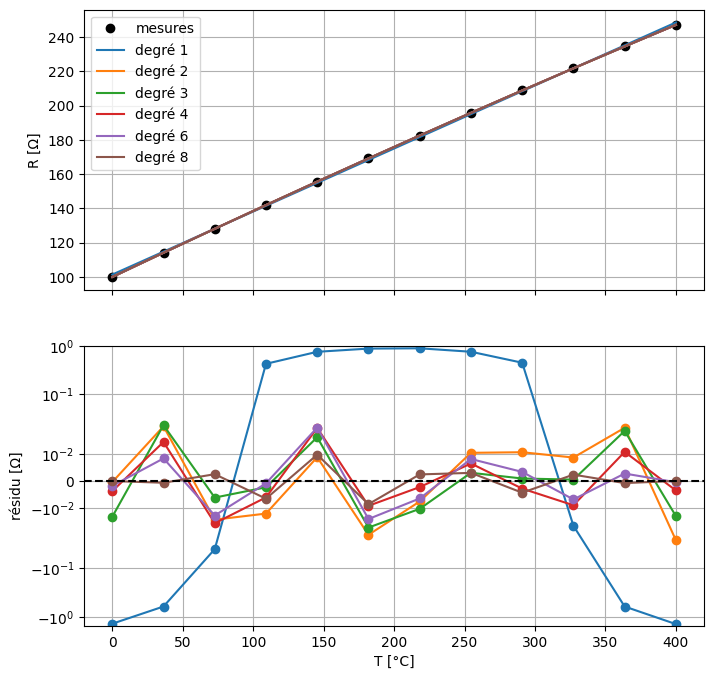

In [21]:
T_fin = np.linspace(Tc.min(), Tc.max(), 400)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
ax1.plot(Tc, Rc, "ko", label="mesures")
for d in degres:
    ax1.plot(T_fin, modele(d, T_fin), label=f"degré {d}")
    ax2.plot(Tc, Rc - modele(d, Tc), "o-", label=f"degré {d}")
ax1.set_ylabel("R [Ω]"); ax1.legend(); ax1.grid()
ax2.axhline(0, color="k", ls="--")
ax2.set_yscale("symlog", linthresh=0.02)   # le degré 1 écraserait les autres en échelle linéaire
ax2.set_xlabel("T [°C]"); ax2.set_ylabel("résidu [Ω]"); ax2.grid()
plt.show()

### Question 3.2 — Résidus des degrés 1 et 2

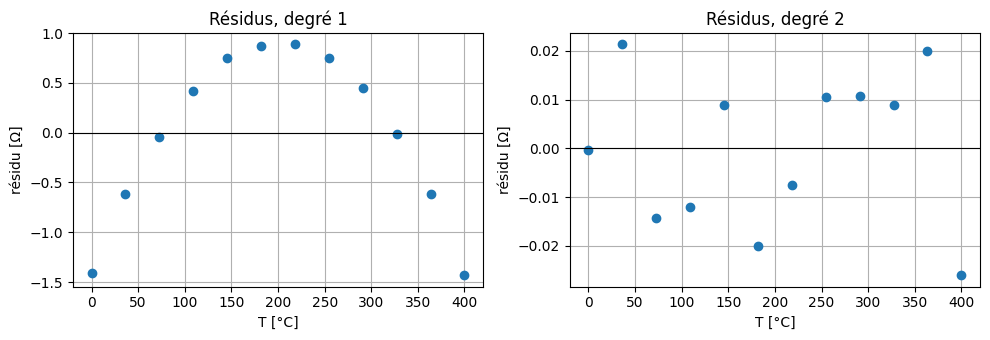

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, d in zip(axs, [1, 2]):
    ax.plot(Tc, Rc - modele(d, Tc), "o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"Résidus, degré {d}"); ax.set_xlabel("T [°C]"); ax.set_ylabel("résidu [Ω]")
    ax.grid()
plt.tight_layout(); plt.show()

Avec le degré 1, les résidus forment une **parabole** d'environ ±1 Ω : c'est le terme $BT^2$ qui manque. Avec le degré 2, ils sont aléatoires, de l'ordre du bruit de mesure (≈ 0,015 Ω). **Le degré 2 est le premier sans structure.**

### Question 3.3 — Validation et extrapolation

On évalue chaque polynôme (ajusté uniquement sur l'étalonnage) sur les deux autres jeux de données.

degré   étalonnage   validation   extrapolation   [Ω]
    1       0.8086       0.7273           5.328
    2       0.0151       0.0157           0.036
    3       0.0127       0.0167           0.192
    4       0.0103       0.0188           0.666
    6       0.0092       0.0186           4.466
    8       0.0047       0.0222         113.204


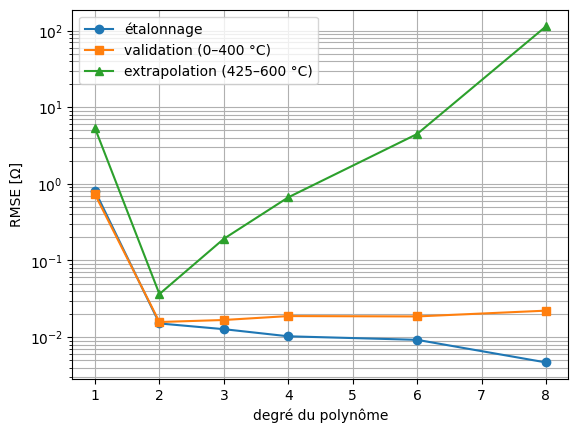

In [23]:
err = np.array([[rmse(d, Tc, Rc), rmse(d, Tv, Rv), rmse(d, Te, Re)] for d in degres])

print("degré   étalonnage   validation   extrapolation   [Ω]")
for d, (e_c, e_v, e_e) in zip(degres, err):
    print(f"{d:5d}   {e_c:10.4f}   {e_v:10.4f}   {e_e:13.3f}")

plt.semilogy(degres, err[:, 0], "o-", label="étalonnage")
plt.semilogy(degres, err[:, 1], "s-", label="validation (0–400 °C)")
plt.semilogy(degres, err[:, 2], "^-", label="extrapolation (425–600 °C)")
plt.xlabel("degré du polynôme"); plt.ylabel("RMSE [Ω]"); plt.legend(); plt.grid(which="both")
plt.show()

Pour visualiser l'extrapolation, on prolonge trois polynômes (degrés 2, 4 et 8) jusqu'à 600 °C et on les superpose aux trois jeux de données. En bas, on trace l'écart entre chaque mesure et le modèle.

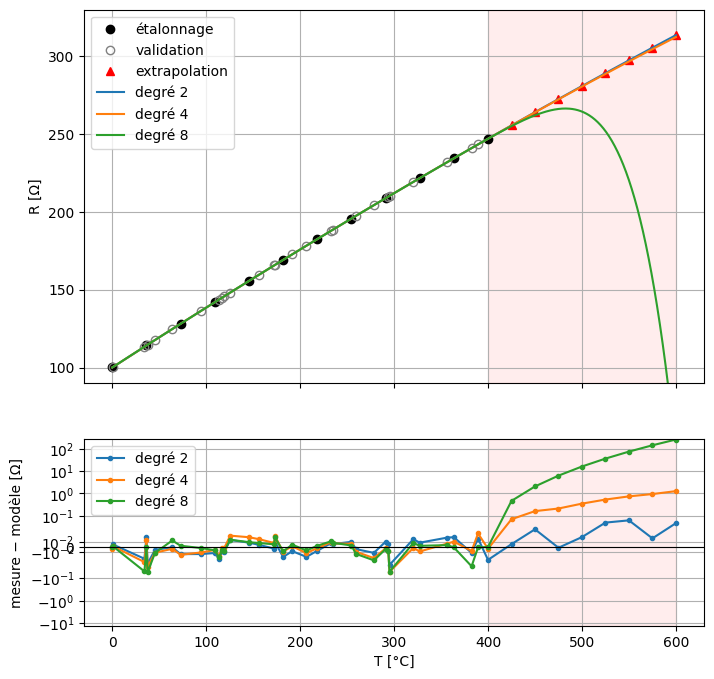

In [24]:
T_tout = np.linspace(0, 600, 600)                   # de 0 °C jusqu'au bout de l'extrapolation
T_all = np.concatenate([Tc, Tv, Te])                # tous les points de mesure
R_all = np.concatenate([Rc, Rv, Re])
ordre = np.argsort(T_all)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 8), height_ratios=[2, 1])
ax1.plot(Tc, Rc, "ko", label="étalonnage")
ax1.plot(Tv, Rv, "o", color="gray", mfc="none", label="validation")
ax1.plot(Te, Re, "r^", label="extrapolation")
for d in [2, 4, 8]:
    ax1.plot(T_tout, modele(d, T_tout), label=f"degré {d}")
    ax2.plot(T_all[ordre], (R_all - modele(d, T_all))[ordre], ".-", label=f"degré {d}")
for ax in (ax1, ax2):
    ax.axvspan(400, 600, color="red", alpha=0.07)   # zone hors de la plage étalonnée
    ax.grid()
ax1.set_ylim(90, 330)                               # le degré 8 sort largement du cadre
ax1.set_ylabel("R [Ω]"); ax1.legend()
ax2.axhline(0, color="k", lw=0.8)
ax2.set_yscale("symlog", linthresh=0.05)            # écarts de 0,01 Ω à plus de 100 Ω
ax2.set_xlabel("T [°C]"); ax2.set_ylabel("mesure − modèle [Ω]"); ax2.legend()
plt.show()

- L'erreur d'**étalonnage** diminue toujours avec le degré : on ajoute des paramètres, l'ajustement colle de plus en plus aux points… y compris au bruit.
- L'erreur de **validation** est minimale vers le degré 2, puis remonte : au-delà, le modèle apprend le bruit (**surajustement**).
- En **extrapolation**, les polynômes de degré élevé divergent hors de la plage étalonnée.

### Question 3.4 — Identification de $R_0$, $A$, $B$

Le polynôme de degré 2 est ajusté en $t = T/100$ : $R = c_0 + c_1 t + c_2 t^2$. En identifiant avec $R_0 + R_0 A\,T + R_0 B\,T^2$ :

$$
R_0 = c_0, \qquad A = \frac{c_1}{100\,R_0}, \qquad B = \frac{c_2}{100^2\,R_0}.
$$

In [25]:
c2, c1, c0 = polys[2]          # polyfit : du plus haut degré au plus bas
R0 = c0
A = c1 / 100 / R0
B = c2 / 100**2 / R0

print(f"R0 = {R0:.4f} Ω       (norme : 100 Ω)")
print(f"A  = {A:.5e} /°C   (norme : 3.9083e-03 /°C)")
print(f"B  = {B:.4e} /°C²  (norme : -5.775e-07 /°C²)")

R0 = 100.0084 Ω       (norme : 100 Ω)
A  = 3.90825e-03 /°C   (norme : 3.9083e-03 /°C)
B  = -5.7971e-07 /°C²  (norme : -5.775e-07 /°C²)


### Question 3.5 — Erreur d'extrapolation en température

On divise l'erreur en ohms par la sensibilité de la sonde, $\approx 0{,}38$ Ω/°C.

In [26]:
sens = 0.38   # Ω/°C
for d in degres:
    print(f"degré {d} :  RMSE extrapolation = {rmse(d, Te, Re):8.3f} Ω  ≈ {rmse(d, Te, Re)/sens:7.2f} °C")

degré 1 :  RMSE extrapolation =    5.328 Ω  ≈   14.02 °C
degré 2 :  RMSE extrapolation =    0.036 Ω  ≈    0.10 °C
degré 3 :  RMSE extrapolation =    0.192 Ω  ≈    0.51 °C
degré 4 :  RMSE extrapolation =    0.666 Ω  ≈    1.75 °C
degré 6 :  RMSE extrapolation =    4.466 Ω  ≈   11.75 °C
degré 8 :  RMSE extrapolation =  113.204 Ω  ≈  297.91 °C


Avec le degré 8, l'erreur hors plage atteint plusieurs centaines de degrés, alors que le degré 2 reste à environ 0,1 °C.

**À retenir :** on choisit le degré le plus faible qui donne des résidus sans structure, on valide sur des points indépendants, et on n'utilise jamais un étalonnage hors de sa plage.

## Exercice 4 — Photodiode en circuit ouvert

En circuit ouvert, $V_{oc} \approx nV_T \ln I_{ph} - nV_T \ln I_s$ et $I_{ph} \propto E$, d'où le modèle logarithmique

$$
V_{oc} = a + b \ln E, \qquad b = n V_T, \qquad V_T = \frac{k_B T}{q}.
$$

### Question 4.1 — Tracés en axes linéaires et logarithmiques

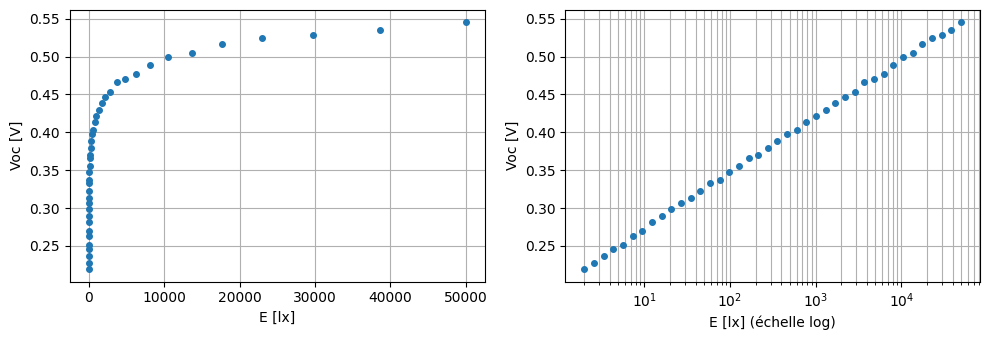

In [27]:
E, V = lire("photodiode_voc.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(E, V, "o", ms=4)
ax1.set_xlabel("E [lx]"); ax1.set_ylabel("Voc [V]"); ax1.grid()
ax2.semilogx(E, V, "o", ms=4)
ax2.set_xlabel("E [lx] (échelle log)"); ax2.set_ylabel("Voc [V]"); ax2.grid(which="both")
plt.tight_layout(); plt.show()

En axes linéaires, la courbe monte très vite puis s'aplatit. Avec un axe des abscisses logarithmique, elle devient une **droite** : c'est la signature d'une loi logarithmique.

### Question 4.2 — Ajustement de $V_{oc} = a + b \ln E$

Le modèle est linéaire en $a$ et $b$ : il suffit de prendre $\mathbf{X} = [\,1,\ \ln E\,]$ et $\mathbf{y} = V_{oc}$.

a = 0.1993 V,   b = 32.13 mV


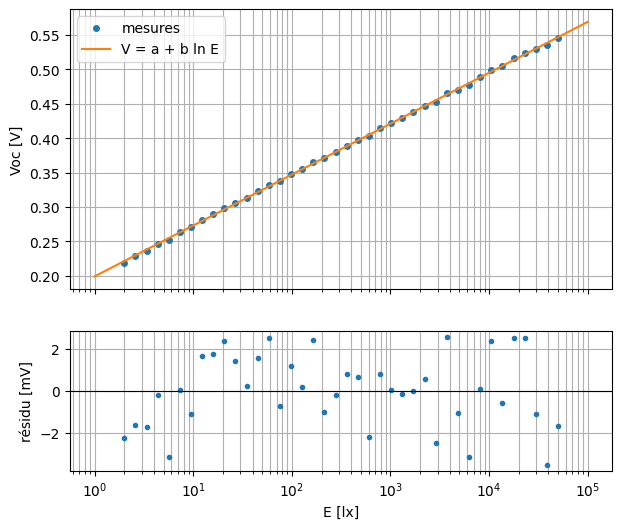

In [28]:
XA = np.column_stack([np.ones_like(E), np.log(E)])
(a, b), *_ = np.linalg.lstsq(XA, V, rcond=None)
rA = V - XA @ np.array([a, b])
print(f"a = {a:.4f} V,   b = {b*1e3:.2f} mV")

# Grille de 200 éclairements entre 1 lx et 1e5 lx pour tracer le modèle.
# geomspace répartit les points régulièrement en échelle log (même nombre
# de points par décade), ce qui donne une courbe lisse sur un axe log.
E_fin = np.geomspace(1, 1e5, 200)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6), height_ratios=[2, 1])
ax1.semilogx(E, V, "o", ms=4, label="mesures")
ax1.semilogx(E_fin, a + b * np.log(E_fin), label="V = a + b ln E")
ax1.set_ylabel("Voc [V]"); ax1.legend(); ax1.grid(which="both")
ax2.semilogx(E, rA * 1e3, "o", ms=3)
ax2.axhline(0, color="k", lw=0.8)
ax2.set_xlabel("E [lx]"); ax2.set_ylabel("résidu [mV]"); ax2.grid(which="both")
plt.show()

La transformation porte sur la variable de **référence** ($E \to \ln E$) : la grandeur mesurée $V_{oc}$ n'est pas transformée, chaque point garde le même poids. Les résidus sont aléatoires, de quelques millivolts, cohérents avec le bruit du convertisseur (≈ 1,5 mV).

### Question 4.3 — Facteur d'idéalité

$b = n V_T$, donc $n = b / V_T$ avec $V_T = k_B T / q$ à 25 °C.

In [29]:
k_B, q = 1.380649e-23, 1.602176634e-19
VT = k_B * 298.15 / q
n_ideal = b / VT
print(f"V_T = {VT*1e3:.2f} mV   ->   n = b / V_T = {n_ideal:.3f}")

V_T = 25.69 mV   ->   n = b / V_T = 1.251


On obtient $n \approx 1{,}25$, dans la plage attendue (entre 1 et 2) pour une photodiode au silicium.